## WLTS 
Testes de análise uso e cobertura

In [1]:
!git clone https://github.com/brazil-data-cube/wlts.py.git

fatal: destination path 'wlts.py' already exists and is not an empty directory.


In [2]:
!pip install earthengine-api geemap

Defaulting to user installation because normal site-packages is not writeable


In [2]:
import os
os.listdir('.')

['LULC_analysis-disposicao-final.ipynb',
 'wlts.py',
 'times.ttf',
 'LULC_analysis.ipynb',
 '.ipynb_checkpoints']

In [4]:
%cd wlts.py

/home/jovyan/dumpsites/WLTS/wlts.py


In [5]:
print(os.getcwd())

/home/jovyan/dumpsites/WLTS/wlts.py


In [6]:
!pip install -e .[all]

Defaulting to user installation because normal site-packages is not writeable
Obtaining file:///home/jovyan/dumpsites/WLTS/wlts.py
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of wlts-py[all] to determine which version is compatible with other requirements. This could take a while.
ERROR: Could not find a version that satisfies the requirement wlts[docs,tests]; extra == "all" (from wlts-py[all]) (from versions: none)
ERROR: No matching distribution found for wlts[docs,tests]; extra == "all"


In [6]:
import ee
ee.Authenticate()
ee.Initialize(project='dumpsites-id')

/home/jovyan/.local/lib/python3.11/site-packages/google/api_core/_python_version_support.py:255: FutureWarning: You are using a Python version (3.11.13) which Google will stop supporting in new releases of google.api_core once it reaches its end of life (2027-10-24). Please upgrade to the latest Python version, or at least Python 3.12, to continue receiving updates for google.api_core past that date.
  warnings.warn(message, FutureWarning)


Enter verification code:  4/1AXlqoi7zJoaAVBIOIhekY9Ncor3Adx0ob6_c3SgBc56TtnkfhC_eS17rwH8



Successfully saved authorization token.


In [7]:
SNISA_data = ee.FeatureCollection("projects/dumpsites-id/assets/data/sinisa_2025_destinacao_final");
print("Pontos:",SNISA_data.size().getInfo())

Pontos: 5918


In [8]:
UFs = ee.FeatureCollection('projects/solvedltda/assets/BR_UF_2021');
SP = UFs.filter(ee.Filter.eq('SIGLA','SP'))
SNISA_sp = SNISA_data.filterBounds(SP)

print("Pontos:",SNISA_sp.size().getInfo())

Pontos: 474


In [9]:
import geemap

Map = geemap.Map(center=[-15, -50], zoom=4)

Map.addLayer(
    SNISA_data,
    {'color': 'red', 'pointSize': 3},
    'Disposal Sites')
Map  # renders the map inline

Map(center=[-15, -50], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright', tr…

## SAMPLE INSIDE A BUFFER

In [10]:
import numpy as np
from shapely.geometry import Point
import geopandas as gpd

def sample_points_in_buffer(lat, lon, radius_m=500, spacing_m=100):
    """
    Returns a list of (lat, lon) tuples within a circular buffer.
    radius_m  : buffer radius in metres
    spacing_m : grid spacing in metres
    """
    # Rough degree-to-metre conversion (works well for most of Brazil)
    deg_per_m = 1 / 111_320
    r_deg = radius_m * deg_per_m

    center = Point(lon, lat)
    buffer = center.buffer(r_deg)

    # Build a grid, keep only points inside the circle
    step = spacing_m * deg_per_m
    xs = np.arange(lon - r_deg, lon + r_deg + step, step)
    ys = np.arange(lat - r_deg, lat + r_deg + step, step)

    pts = [
        (y, x) for x in xs for y in ys
        if buffer.contains(Point(x, y))
    ]
    return pts  # list of (lat, lon)

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.patches import Circle

def plot_buffer_samples(radius_m=500, spacing_m=150):
    
    deg_per_m = 1 / 111_320
    r_deg = radius_m * deg_per_m
    step  = spacing_m * deg_per_m

    # Generate grid points inside circle
    xs = np.arange(-r_deg, r_deg + step, step)
    ys = np.arange(-r_deg, r_deg + step, step)
    xx, yy = np.meshgrid(xs, ys)
    mask = (xx**2 + yy**2) <= r_deg**2
    pts_x = xx[mask]
    pts_y = yy[mask]

    # Convert to metres for display
    pts_xm = pts_x / deg_per_m
    pts_ym = pts_y / deg_per_m

    fig, ax = plt.subplots(figsize=(6, 6))

    # Buffer circle
    circle = Circle((0, 0), radius_m, color='steelblue', alpha=0.08, zorder=1)
    ax.add_patch(circle)
    circle_border = Circle((0, 0), radius_m, fill=False,
                            edgecolor='steelblue', linewidth=1.5, zorder=2)
    ax.add_patch(circle_border)

    # Concentric reference rings
    for f in [0.25, 0.5, 0.75]:
        ring = Circle((0, 0), radius_m * f, fill=False,
                      edgecolor='gray', linewidth=0.5, linestyle='--', alpha=0.4, zorder=1)
        ax.add_patch(ring)

    # Cardinal dashed lines
    ax.axhline(0, color='gray', linewidth=0.5, linestyle='--', alpha=0.4, zorder=1)
    ax.axvline(0, color='gray', linewidth=0.5, linestyle='--', alpha=0.4, zorder=1)

    # Sample points
    ax.scatter(pts_xm, pts_ym, s=30, color='teal',
               edgecolors='#0a5c4a', linewidths=0.8,
               alpha=0.8, zorder=3, label=f'Sample points (n={len(pts_xm)})')

    # Center point
    ax.scatter(0, 0, s=80, color='darkorange',
               edgecolors='#7a3800', linewidths=1,
               zorder=4, label='Center point')

    # Radius annotation
    ax.annotate('', xy=(radius_m, 0), xytext=(0, 0),
                arrowprops=dict(arrowstyle='->', color='darkorange',
                                lw=1.2, linestyle='dashed'))
    ax.text(radius_m / 2, radius_m * 0.04,
            f'{radius_m} m', ha='center', fontsize=9, color='darkorange')

    # Spacing annotation (between first two horizontally adjacent points)
    if len(pts_xm) >= 2:
        row_mask = np.abs(pts_ym) < (spacing_m * 0.1)
        row_x = np.sort(pts_xm[row_mask])
        if len(row_x) >= 2:
            ax.annotate('', xy=(row_x[1], spacing_m * 0.35),
                        xytext=(row_x[0], spacing_m * 0.35),
                        arrowprops=dict(arrowstyle='<->', color='gray', lw=1))
            ax.text((row_x[0] + row_x[1]) / 2, spacing_m * 0.45,
                    f'{spacing_m} m', ha='center', fontsize=8, color='gray')

    lim = radius_m * 1.25
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect('equal')
    ax.set_xlabel('metres (EW)', fontsize=10)
    ax.set_ylabel('metres (NS)', fontsize=10)
    ax.set_title(f'Buffer r={radius_m} m  |  spacing={spacing_m} m  |  n={len(pts_xm)} points',
                 fontsize=11)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(False)
    plt.tight_layout()
    plt.show()
    print(f'Total WLTS queries per center point: {len(pts_xm)}')



In [12]:
from ipywidgets import interact, IntSlider

interact(
    plot_buffer_samples,
    radius_m  = IntSlider(min=100, max=1500, step=50,  value=500,  description='Radius (m)'),
    spacing_m = IntSlider(min=25,  max=400,  step=25,  value=150,  description='Spacing (m)')
)

interactive(children=(IntSlider(value=500, description='Radius (m)', max=1500, min=100, step=50), IntSlider(va…

<function __main__.plot_buffer_samples(radius_m=500, spacing_m=150)>

## WLTS

In [13]:
from wlts import WLTS

# You should create a wlts object attached to a given service
# Specify the URL of the WLTS instance to be used
service = WLTS('https://data.inpe.br/bdc/wlts/v1/')

# Returns the list of collections available on the service
# print(service.collections)

In [14]:
import pandas as pd

# Convert EE FeatureCollection to DataFrame
features = SNISA_sp.getInfo()["features"]

df = pd.DataFrame([
    {   "id": f["id"],
        **f["properties"],
        "geometry": f["geometry"]
    }
    for f in features
])

# Random subsample of 100 points
# df = df.sample(
#     n=min(5, len(df)),
#     random_state=42
# ).reset_index(drop=True)

print(f"Selected {len(df)} points")
df.head()

Selected 474 points


,id,A unidade,Ano de in�,CAPITAL,CNPJ,Capacida_1,Capacidade,Caracteriz,Controle d,CÓDIGO DO,...,Quantidade,RESPONDEU,SECRETARIA,Sistemas d,Situação,Tipo de li,Tipo de un,UF,Área (Km�,geometry
0,00000000000000000dcb,Sim,1999,,46.634.432/0001-55,,,,"2-Sim, é feita a pesagem na entrada e na saída...",3508405,...,19.254,Sim,"SECRETARIA DE MEIO AMBIENTE,OBRAS E SERVIÇOS U...",1-Impermeabilização de base \n2-Drenagem de li...,,Licença de operação,Aterro controlado,SP,"260,23","{'type': 'Point', 'coordinates': [-47.13619852..."
1,00000000000000000e60,Sim,2022,,49.345.911/0001-40,,,1-Queima em “flare” central após sucção forçada,"2-Sim, é feita a pesagem na entrada e na saída...",3519907,...,3.771,Sim,SECRETARIA MUNICIPAL DE AGRICULTURA E MEIO AMB...,1-Impermeabilização de base \n4-Sistema de rec...,,Licença de operação,Aterro controlado,SP,"594,97","{'type': 'Point', 'coordinates': [-51.05027257..."
2,00000000000000000dbc,Não,,,46.189.734/0001-61,,,,,3507308,...,2.067,Sim,SECRETARIA DA AGRCULTURA E MEIO AMBIENTE,,Desativado,,Aterro controlado,SP,"122,11","{'type': 'Point', 'coordinates': [-48.78079972..."
3,00000000000000000e75,Não,,,49.556.863/0001-39,,,,,3521309,...,6.470,Sim,SECRETARIA DE ENGENHARIA OBRAS TRANSITO E MEIO...,,Encerrado sem processo de remediação,,Aterro controlado,SP,"466,46","{'type': 'Point', 'coordinates': [-47.99705474..."
4,00000000000000000e86,Não,,,49.979.255/0001-37,,,,,3522703,...,18.770,Sim,SECRETARIA DE DESENVOLVIMENTO AMBIENTAL,,Desativado,,Aterro controlado,SP,"996,75","{'type': 'Point', 'coordinates': [-48.81489846..."


In [ ]:
# Check for missing/null ids
n_null = df["id"].isna().sum()
print(f"Points with null id: {n_null}")

# Check for empty-string ids (in case GEE returns "" instead of NaN)
n_empty = (df["id"].astype(str).str.strip() == "").sum()
print(f"Points with empty-string id: {n_empty}")

# Check for duplicate ids too, since that would also break a clean join
n_dupes = df["id"].duplicated().sum()
print(f"Duplicate ids: {n_dupes}")

# Show the problem rows, if any
problem_rows = df[df["id"].isna() | (df["id"].astype(str).str.strip() == "")]
problem_rows

In [ ]:
def aggregate_trajectories(trajectories):
    """
    For each year, pick the most common land-use class (majority vote).
    Returns a dict in the same shape wlts normally returns.
    """
    year_votes = {}  # {year: [class, class, ...]}

    for traj in trajectories:
        # wlts returns something like: {'trajectory': [{'date': ..., 'class': ...}, ...]}
        for entry in traj.get("trajectory", []):
            year = entry["date"]
            cls  = entry["class"]
            year_votes.setdefault(year, []).append(cls)

    majority = {
        year: Counter(classes).most_common(1)[0][0]
        for year, classes in year_votes.items()
    }

    return {"trajectory": [{"date": y, "class": c} for y, c in sorted(majority.items())]}

In [ ]:
def test_list_collection(respx_mock_all):
    client = wlts.WLTS(url=BASE_URL, lccs_url=LCCS_URL, language='pt-br')
    collections = client.collections
    assert isinstance(collections, list)
    assert "prodes_amz" in collections

In [ ]:
# Pick the first sampled point
collections = "ibge_cobertura_uso_terra,mapbiomas-v10"
collections = "mapbiomas-v10"


row = df.iloc[0]
geom = row["geometry"]
lon, lat = geom["coordinates"]

start_date = 2024
end_date   = 2024

traj = service.tj(
    latitude=lat,
    longitude=lon,
    collections=collections,
    start_date = start_date,
    end_date = end_date
)

traj

### EXAMPLE WITH SUB SAMPLING

In [ ]:
DIE

In [ ]:
import time
import httpx
import pandas as pd


globalBounds = ee.Geometry.BBox(-180, -90, 180, 90);
pointsGeometry = SNISA_data.filterBounds(globalBounds);
features = pointsGeometry.getInfo()["features"]

df = pd.DataFrame([
    {   "id": f["id"],
        **f["properties"],
        "geometry": f["geometry"]
    }
    for f in features
])

results = []
all_sub_points = []

for idx, row in df.iterrows():
    print(f"POINT ID: {idx}")
    geom = row["geometry"]
    lon, lat = geom["coordinates"]

    sub_points = sample_points_in_buffer(
        lat=lat,
        lon=lon,
        radius_m=200,
        spacing_m=50
    )
    
    for s_lat, s_lon in sub_points:
        all_sub_points.append({
            "parent_id": idx,
            "lat": s_lat,
            "lon": s_lon
        })

    trajectories = []

    for s_lat, s_lon in sub_points:

        for attempt in range(3):

            try:
                res = service.tj(
                    latitude=s_lat,
                    longitude=s_lon,
                    collections=collections,
                    start_date=start_date,
                    end_date=end_date,
                    # target_system="simplifiedlegendtm-1"
                )

                trajectories.append(res)
                print(f"Point ({s_lat:.5f}, {s_lon:.5f}) appended")
                break

            except httpx.ReadTimeout:

                if attempt < 2:
                    print(
                        f"Timeout at ({s_lat:.5f}, {s_lon:.5f}) "
                        f"- retry {attempt+1}/3"
                    )
                    time.sleep(5)

                else:
                    print(
                        f"Skipped ({s_lat:.5f}, {s_lon:.5f})"
                    )

    if len(trajectories) == 0:
        print(f"No successful trajectories for point {idx}")
        continue

    aggregated = aggregate_trajectories(trajectories)

    results.append({
        "id": idx,
        **aggregated
    })

    # checkpoint after every point
    pd.DataFrame(results).to_csv(
        "trajectory_results_checkpoint_buffer-100-spacing-50.csv",
        index=False
    )

    print(
        f"Done point {idx+1}/{len(df)} "
        f"({len(trajectories)} trajectories)"
    )

results_df = pd.DataFrame(results)

results_df.to_csv(
    "trajectory_results_final_buffer-100-spacing-50.csv",
    index=False
)

results_df.head()

### EXAMPLE WITHOUT SUB SAMPLING

In [15]:
import ee
import pandas as pd

col_tipo = "Tipo de un"
col_val = "Quantida_5"

globalBounds = ee.Geometry.BBox(-180, -90, 180, 90)
pointsGeometry = SNISA_data.filterBounds(globalBounds)   # no server-side value filter

features = pointsGeometry.getInfo()["features"]

df = pd.DataFrame([
    {"id": f["id"], **f["properties"], "geometry": f["geometry"]}
    for f in features
])

# Parse numbers stored as numbers or as Brazilian-style text ("1.234,56")
def to_number(x):
    if x is None:
        return float("nan")
    if isinstance(x, (int, float)):
        return float(x)
    s = str(x).strip().replace(" ", "")
    if "," in s:
        s = s.replace(".", "").replace(",", ".")
    return pd.to_numeric(s, errors="coerce")

df[col_val] = df[col_val].map(to_number)

# Keep only rows with a numeric value >= 0
df = df[df[col_val] >= 0].reset_index(drop=True)

print(len(df))   # 3176

3176


In [16]:
df

,id,A unidade,Ano de in�,CAPITAL,CNPJ,Capacida_1,Capacidade,Caracteriz,Controle d,CÓDIGO DO,...,Quantidade,RESPONDEU,SECRETARIA,Sistemas d,Situação,Tipo de li,Tipo de un,UF,Área (Km�,geometry
0,000000000000000000ca,Sim,2012,,01.613.321/0001-24,,,1-Queima em “flare” central após sucção forçada,"2-Sim, é feita a pesagem na entrada e na saída...",1502152,...,31.631,Sim,SECRETARIA DE PLANEJAMENTO E ASSUNTOS ECONÔMICOS,6-Drenagem ou captação de gases (sucção forçad...,,Não possui licença ambiental,Aterro controlado,PA,"3.146,82","{'type': 'Point', 'coordinates': [-49.87760034..."
1,00000000000000000108,Sim,2013,,22.980.999/0001-15,,,,"5-Sim, é feita a pesagem com registro em siste...",1505536,...,114.886,Sim,SECRETARIA MUNICIPAL DE SERVIÇOS URBANOS,2-Drenagem de lixiviados \n5-Drenagem ou capta...,,Não possui licença ambiental,Aterro controlado,PA,"6.885,79","{'type': 'Point', 'coordinates': [-49.90418104..."
2,00000000000000000121,Sim,2003,,05.182.233/0001-76,,,,"2-Sim, é feita a pesagem na entrada e na saída...",1506807,...,126.049,Sim,SECRETARIA MUNICIPAL DE SERVIÇOS URBANOS,2-Drenagem de lixiviados \n5-Drenagem ou capta...,,Não possui licença ambiental,Aterro controlado,PA,"17.898,39","{'type': 'Point', 'coordinates': [-54.69960088..."
3,0000000000000000019e,Sim,2020,,01.618.402/0001-17,,,1-Queima em “flare” central após sucção forçad...,1-Não possui pesagem rotineira,1712157,...,891,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE,5-Drenagem ou captação de gases (sem sucção fo...,,Não possui licença ambiental,Aterro controlado,TO,"468,01","{'type': 'Point', 'coordinates': [-46.50989994..."
4,000000000000000001b5,Sim,2016,,00.007.401/0001-73,,,,1-Não possui pesagem rotineira,1715754,...,3.677,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE,5-Drenagem ou captação de gases (sem sucção fo...,,Licença de operação,Aterro controlado,TO,"1.708,98","{'type': 'Point', 'coordinates': [-48.40260106..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3171,000000000000000016f2,Sim,1996,,01.067.990/0001-48,,,,1-Não possui pesagem rotineira,5219407,...,3.567,Sim,SECRETARIA MEIO AMBIENTE,,,Não possui licença ambiental,Lixão ou vazadouro,GO,"1.357,20","{'type': 'Point', 'coordinates': [-53.17253713..."
3172,00000000000000001706,Sim,2016,,01.343.086/0001-18,,,,1-Não possui pesagem rotineira,5220504,...,4.329,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE,,,Não possui licença ambiental,Lixão ou vazadouro,GO,"5.521,77","{'type': 'Point', 'coordinates': [-51.95860038..."
3173,00000000000000001707,Sim,2011,,01.068.030/0001-00,,,,1-Não possui pesagem rotineira,5220603,...,12.039,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE,,,Não possui licença ambiental,Lixão ou vazadouro,GO,"2.349,92","{'type': 'Point', 'coordinates': [-48.60196301..."
3174,00000000000000001709,Sim,2014,,01.740.489/0001-09,,,,1-Não possui pesagem rotineira,5220702,...,1.602,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE E TURISMO,,,Não possui licença ambiental,Lixão ou vazadouro,GO,"1.611,85","{'type': 'Point', 'coordinates': [-46.25059876..."


In [17]:
import time
import httpx
import pandas as pd


records = []

for idx, row in df.iterrows():
    point_id = row["id"]
    print(f"POINT ID: {point_id}")
    geom = row["geometry"]
    lon, lat = geom["coordinates"]

    trajectories = []
    for attempt in range(3):
        try:
            res = service.tj(
                latitude=lat,
                longitude=lon,
                collections=collections,
                start_date=start_date,
                end_date=end_date
            )
            trajectories.append(res)
            # print(res)
            print(f"Point ({lat:.5f}, {lon:.5f}) appended")
            break
        except httpx.ReadTimeout:
            if attempt < 2:
                print(
                    f"Timeout at ({lat:.5f}, {lon:.5f}) "
                    f"- retry {attempt+1}/3"
                )
                time.sleep(5)
            else:
                print(f"Skipped ({lat:.5f}, {lon:.5f})")

    if res is None:
        print(f"No successful trajectory for point {point_id}")
        continue

    trajectory = res.get("result", {}).get("trajectory", [])
    if not trajectory:
        print(f"Empty trajectory for point {point_id}")
        continue

    for entry in trajectory:
        records.append({
            "id": point_id,            # matches df.index, for joining
            "lat": lat,
            "lon": lon,
            "collection": entry["class"] and entry["collection"],
            "class": entry["class"],
            "date": entry["date"],
        })
    
    # checkpoint after every point
    pd.DataFrame(records).to_csv(
        "trajectory_results_checkpoint.csv",
        index=False
    )
    print(f"Done point {point_id} ({len(trajectory)} entries)")

results_df = pd.DataFrame(records)
results_df.to_csv("trajectory_results_final.csv", index=False)
results_df.head()

POINT ID: 000000000000000000ca


NameError: name 'start_date' is not defined

In [19]:
%pwd


'/home/jovyan/dumpsites/WLTS/wlts.py'

In [18]:
import pandas as pd
results_df = pd.read_csv('trajectory_results_final.csv')
results_df

,id,lat,lon,collection,class,date
0,000000000000000000ca,-6.496589,-49.877600,mapbiomas-v10,Pastagem,2024
1,00000000000000000108,-6.006324,-49.904181,mapbiomas-v10,Mineração,2024
2,00000000000000000121,-2.438491,-54.699601,mapbiomas-v10,Área Urbanizada,2024
3,0000000000000000019e,-12.784702,-46.509900,mapbiomas-v10,Pastagem,2024
4,000000000000000001b5,-13.044699,-48.402601,mapbiomas-v10,Área Urbanizada,2024
...,...,...,...,...,...,...
3465,000000000000000016f2,-17.340512,-53.172537,mapbiomas-v10,Mosaico de Usos,2024
3466,00000000000000001706,-18.306701,-51.958600,mapbiomas-v10,Área Urbanizada,2024
3467,00000000000000001707,-16.719966,-48.601963,mapbiomas-v10,Formação Savânica,2024
3468,00000000000000001709,-14.799199,-46.250599,mapbiomas-v10,Pastagem,2024


In [19]:
import pandas as pd

results_df = pd.read_csv('trajectory_results_final.csv')

final_df = results_df.merge(
    df,
    on="id",
    how="inner"      # keep only ids present in both tables
)

print(len(final_df))   # expected: 3176

3176


In [20]:
ibge_dates = (
    final_df[final_df["collection"] == "ibge_cobertura_uso_terra"]["date"]
    .unique()
)
sorted(ibge_dates)

[]

In [21]:
final_df

,id,lat,lon,collection,class,date,A unidade,Ano de in�,CAPITAL,CNPJ,...,Quantidade,RESPONDEU,SECRETARIA,Sistemas d,Situação,Tipo de li,Tipo de un,UF,Área (Km�,geometry
0,000000000000000000ca,-6.496589,-49.877600,mapbiomas-v10,Pastagem,2024,Sim,2012,,01.613.321/0001-24,...,31.631,Sim,SECRETARIA DE PLANEJAMENTO E ASSUNTOS ECONÔMICOS,6-Drenagem ou captação de gases (sucção forçad...,,Não possui licença ambiental,Aterro controlado,PA,"3.146,82","{'type': 'Point', 'coordinates': [-49.87760034..."
1,00000000000000000108,-6.006324,-49.904181,mapbiomas-v10,Mineração,2024,Sim,2013,,22.980.999/0001-15,...,114.886,Sim,SECRETARIA MUNICIPAL DE SERVIÇOS URBANOS,2-Drenagem de lixiviados \n5-Drenagem ou capta...,,Não possui licença ambiental,Aterro controlado,PA,"6.885,79","{'type': 'Point', 'coordinates': [-49.90418104..."
2,00000000000000000121,-2.438491,-54.699601,mapbiomas-v10,Área Urbanizada,2024,Sim,2003,,05.182.233/0001-76,...,126.049,Sim,SECRETARIA MUNICIPAL DE SERVIÇOS URBANOS,2-Drenagem de lixiviados \n5-Drenagem ou capta...,,Não possui licença ambiental,Aterro controlado,PA,"17.898,39","{'type': 'Point', 'coordinates': [-54.69960088..."
3,0000000000000000019e,-12.784702,-46.509900,mapbiomas-v10,Pastagem,2024,Sim,2020,,01.618.402/0001-17,...,891,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE,5-Drenagem ou captação de gases (sem sucção fo...,,Não possui licença ambiental,Aterro controlado,TO,"468,01","{'type': 'Point', 'coordinates': [-46.50989994..."
4,000000000000000001b5,-13.044699,-48.402601,mapbiomas-v10,Área Urbanizada,2024,Sim,2016,,00.007.401/0001-73,...,3.677,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE,5-Drenagem ou captação de gases (sem sucção fo...,,Licença de operação,Aterro controlado,TO,"1.708,98","{'type': 'Point', 'coordinates': [-48.40260106..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3171,000000000000000016f2,-17.340512,-53.172537,mapbiomas-v10,Mosaico de Usos,2024,Sim,1996,,01.067.990/0001-48,...,3.567,Sim,SECRETARIA MEIO AMBIENTE,,,Não possui licença ambiental,Lixão ou vazadouro,GO,"1.357,20","{'type': 'Point', 'coordinates': [-53.17253713..."
3172,00000000000000001706,-18.306701,-51.958600,mapbiomas-v10,Área Urbanizada,2024,Sim,2016,,01.343.086/0001-18,...,4.329,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE,,,Não possui licença ambiental,Lixão ou vazadouro,GO,"5.521,77","{'type': 'Point', 'coordinates': [-51.95860038..."
3173,00000000000000001707,-16.719966,-48.601963,mapbiomas-v10,Formação Savânica,2024,Sim,2011,,01.068.030/0001-00,...,12.039,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE,,,Não possui licença ambiental,Lixão ou vazadouro,GO,"2.349,92","{'type': 'Point', 'coordinates': [-48.60196301..."
3174,00000000000000001709,-14.799199,-46.250599,mapbiomas-v10,Pastagem,2024,Sim,2014,,01.740.489/0001-09,...,1.602,Sim,SECRETARIA MUNICIPAL DE MEIO AMBIENTE E TURISMO,,,Não possui licença ambiental,Lixão ou vazadouro,GO,"1.611,85","{'type': 'Point', 'coordinates': [-46.25059876..."


In [22]:
# Check for missing/null ids
n_null = final_df["id"].isna().sum()
print(f"Points with null id: {n_null}")

# Check for empty-string ids (in case GEE returns "" instead of NaN)
n_empty = (final_df["id"].astype(str).str.strip() == "").sum()
print(f"Points with empty-string id: {n_empty}")

# Check for duplicate ids too, since that would also break a clean join
n_dupes = final_df["id"].duplicated().sum()
print(f"Duplicate ids: {n_dupes}")

# Show the problem rows, if any
problem_rows = final_df[final_df["id"].isna() | (final_df["id"].astype(str).str.strip() == "")]
problem_rows

Points with null id: 0
Points with empty-string id: 0
Duplicate ids: 0


,id,lat,lon,collection,class,date,A unidade,Ano de in�,CAPITAL,CNPJ,...,Quantidade,RESPONDEU,SECRETARIA,Sistemas d,Situação,Tipo de li,Tipo de un,UF,Área (Km�,geometry


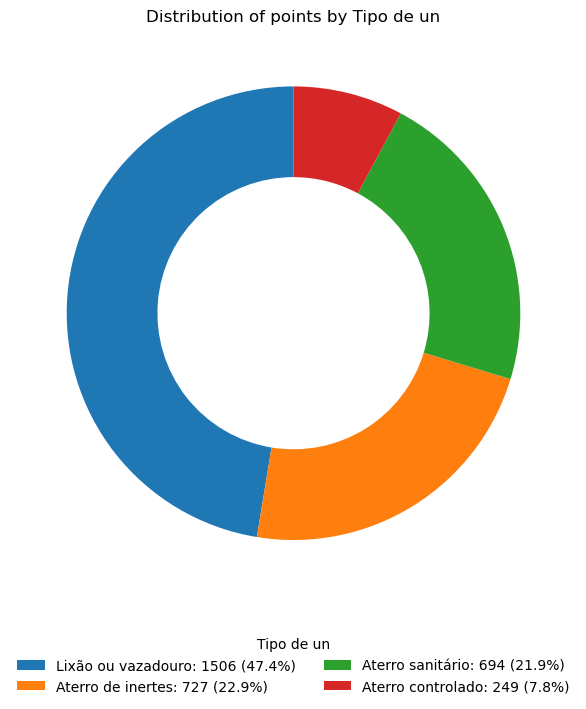

In [23]:
import matplotlib.pyplot as plt

tipo_counts = (
    final_df.drop_duplicates("id")["Tipo de un"]
    .value_counts()
)
total = tipo_counts.sum()
fig, ax = plt.subplots(figsize=(9, 9))

wedges, _ = ax.pie(
    tipo_counts,
    startangle=90,
    wedgeprops=dict(width=0.4),  # Donut chart
)

legend_labels = [
    f"{label}: {count} ({count / total:.1%})"
    for label, count in tipo_counts.items()
]

ax.legend(
    wedges,
    legend_labels,
    title="Tipo de un",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.05),  # Centered below the chart
    ncol=2,                       # Adjust depending on number of categories
    frameon=False
)

ax.set_title("Distribution of points by Tipo de un")
plt.subplots_adjust(bottom=0.25)  # Make room for the legend
plt.show()

In [24]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

font_path = "../times.ttf"

fm.fontManager.addfont(font_path)

font_name = fm.FontProperties(fname=font_path).get_name()

plt.rcParams["font.family"] = font_name

print(font_name)


Times New Roman


mapbiomas-v10 (2024): 3176 rows

mapbiomas-v10 (2024) - total points: 3176

[1] Points per class (sorted by size):
                                n_points  % of total
Urban Area                           972       30.60
Pasture                              744       23.43
Mosaic of Uses                       496       15.62
Savanna Formation                    260        8.19
Forest Formation                     251        7.90
Soybean                              112        3.53
Other Non-vegetated Areas             89        2.80
Other Temporary Crops                 63        1.98
Sugar cane                            61        1.92
Grassland Formation                   22        0.69
Floodable Forest                      22        0.69
Mining                                17        0.54
Forest Plantation                     17        0.54
Wetland                               16        0.50
River, Lake and Ocean                 16        0.50
Other Perennial Crops                

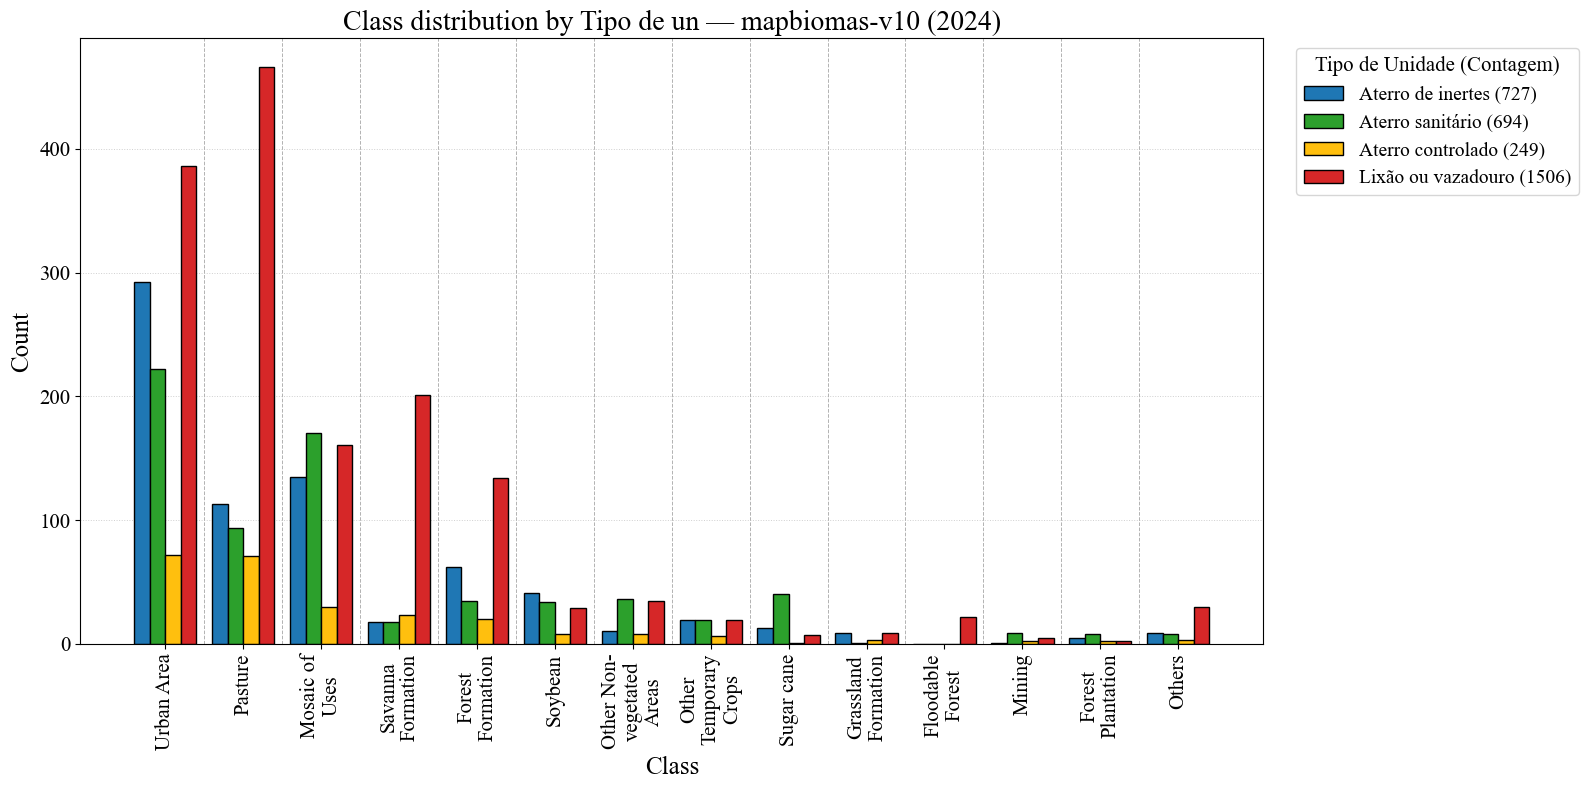

In [27]:
import re
import textwrap

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# Set font to Times New Roman
# ============================================================
plt.rcParams["font.family"] = "Times New Roman"

# ============================================================
# 1. Map each category type to a specific color
# ============================================================
mapa_de_cores = {
    'Aterro sanitário': '#2ca02c',     # Green
    'Aterro controlado': '#ffbf0e',    # Yellow
    'Lixão ou vazadouro': '#d62728',   # Red
    'Aterro de inertes': '#1f77b4'     # Blue
}

# ============================================================
# 2. Define category display order
# ============================================================
ordem_categorias = [
    'Aterro de inertes',
    'Aterro sanitário',
    'Aterro controlado',
    'Lixão ou vazadouro'
]

coluna_tipo = "Tipo de un"

# ============================================================
# 3. English translation
# ============================================================
traducao_classes = {

    # 1. Forest
    'Floresta': 'Forest',
    'Formação Florestal': 'Forest Formation',
    'Floresta Alagável': 'Floodable Forest',
    'Formação Savânica': 'Savanna Formation',
    'Savana Alagada (beta)': 'Flooded Savanna (beta)',
    'Mangue': 'Mangrove',
    'Restinga Arbórea': 'Wooded Sandbank Vegetation',

    # 2. Herbaceous or Shrubby Vegetation
    'Vegetação Herbácea e Arbustiva': 'Herbaceous or Shrubby Vegetation',
    'Formação Campestre': 'Grassland Formation',
    'Formação Herbáceo Arbustiva': 'Herbaceous and Shrub Formation',
    'Campo Alagado e Área Pantanosa': 'Wetland',
    'Marisma (beta)': 'Salt Marsh (beta)',
    'Restinga Herbácea': 'Herbaceous Sandbank Vegetation',
    'Apicum': 'Hypersaline Tidal Flat',
    'Afloramento Rochoso': 'Rocky Outcrop',

    # 3. Farming
    'Agropecuária': 'Farming',
    'Pastagem': 'Pasture',
    'Agricultura': 'Agriculture',
    'Lavoura Temporária': 'Temporary Crop',
    'Soja': 'Soybean',
    'Cana': 'Sugar cane',
    'Arroz': 'Rice',
    'Algodão (beta)': 'Cotton (beta)',
    'Outras Lavouras Temporárias': 'Other Temporary Crops',
    'Lavoura Perene': 'Perennial Crop',
    'Café': 'Coffee',
    'Citrus': 'Citrus',
    'Dendê': 'Palm Oil',
    'Outras Lavouras Perenes': 'Other Perennial Crops',
    'Silvicultura': 'Forest Plantation',
    'Mosaico de Usos': 'Mosaic of Uses',

    # 4. Non-vegetated area
    'Área não vegetada': 'Non-vegetated Area',
    'Praia, Duna e Areal': 'Beach, Dune and Sand Spot',
    'Área Urbanizada': 'Urban Area',
    'Mineração': 'Mining',
    'Usina Fotovoltaica': 'Photovoltaic Power Plant',
    'Parque eólico (beta)': 'Wind Farm (beta)',
    'Outras Áreas não Vegetadas': 'Other Non-vegetated Areas',

    # 5. Water
    "Corpo D'água": 'Water',
    'Rio, Lago e Oceano': 'River, Lake and Ocean',
    'Aquicultura': 'Aquaculture'
}


# ============================================================
# 4. Helpers
# ============================================================
def remover_numeros(nome):
    """Remove ALL numerical prefixes."""
    return re.sub(r'^[\d.]+\s*', '', str(nome)).strip()


def quebrar_nome(nome, max_linhas=3, largura_inicial=12):
    """Wrap a label into at most `max_linhas` lines (short names stay on one line)."""
    for largura in range(largura_inicial, 80):
        linhas = textwrap.wrap(nome, width=largura)
        if len(linhas) <= max_linhas:
            return "\n".join(linhas)
    return nome


# ============================================================
# 5. Data
# ============================================================
years_by_collection = {
    # "ibge_cobertura_uso_terra": "2020",
    "mapbiomas-v10": "2024",
}

# ============================================================
# 6. Generate plots
# ============================================================
for collection, year in years_by_collection.items():

    coll_group = final_df[
        (final_df["collection"] == collection)
        & (final_df["date"].astype(str) == year)
    ].copy()

    print(f"{collection} ({year}): {len(coll_group)} rows")

    if coll_group.empty:
        print(f"No data for {collection} in {year}, skipping plot")
        continue

    # --------------------------------------------------------
    # Remove numerical prefixes from class names
    # --------------------------------------------------------
    coll_group["class_clean"] = coll_group["class"].apply(remover_numeros)

    # --------------------------------------------------------
    # Create pivot table
    # --------------------------------------------------------
    pivot_df = (
        coll_group
        .groupby(["class_clean", coluna_tipo])
        .size()
        .unstack(fill_value=0)
    )

    # --------------------------------------------------------
    # Filter categories while preserving desired order
    # --------------------------------------------------------
    tipos_unicos = [
        t for t in ordem_categorias
        if t in pivot_df.columns
    ]

    # ========================================================
    # ORDER CLASSES BY TOTAL NUMBER OF OCCURRENCES
    # ========================================================
    class_totals = pivot_df[tipos_unicos].sum(axis=1)

    # Highest occurrence -> lowest occurrence
    classes = class_totals.sort_values(ascending=False).index

    # Reorder pivot table according to occurrence
    pivot_df = pivot_df.loc[classes]

    # ========================================================
    # PERCENTAGE STATISTICS (computed BEFORE the "Others" merge)
    # ========================================================
    # Short English names for the types (keeps tables readable)
    tipo_curto = {
        'Aterro de inertes': 'Inert',
        'Aterro sanitário': 'Sanitary',
        'Aterro controlado': 'Controlled',
        'Lixão ou vazadouro': 'Open dump',
    }

    counts = pivot_df[tipos_unicos].copy()
    counts.index = [traducao_classes.get(c, c) for c in counts.index]
    counts.columns = [tipo_curto.get(t, t) for t in counts.columns]
    counts.index.name = None
    counts.columns.name = None

    total_points = counts.values.sum()
    n_per_class = counts.sum(axis=1)

    share_of_total = n_per_class / total_points * 100                # % of all points per class
    type_given_class = counts.div(n_per_class, axis=0) * 100         # P(type | class)
    class_given_type = counts.div(counts.sum(axis=0), axis=1) * 100  # P(class | type)
    base_rate = counts.sum(axis=0) / total_points * 100              # % of each type overall
    lift = type_given_class.div(base_rate, axis=1)                   # over/under-representation

    pd.set_option("display.width", 200)
    pd.set_option("display.max_columns", None)

    print(f"\n{'=' * 70}")
    print(f"{collection} ({year}) - total points: {total_points}")
    print('=' * 70)

    # Table 1: how many points per class and what share of the total
    t1 = pd.DataFrame({
        "n_points": n_per_class,
        "% of total": share_of_total.round(2),
    })
    print("\n[1] Points per class (sorted by size):")
    print(t1.to_string())

    # Table 2: P(type | class)
    print("\n[2] P(type | class) - each ROW sums to 100%:")
    print(type_given_class.round(1).to_string())

    # Table 3: P(class | type)
    print("\n[3] P(class | type) - each COLUMN sums to 100%:")
    print(class_given_type.round(1).to_string())

    # Table 4: base rate and lift
    print("\n[4] Base rate of each type (% of all points):")
    print(base_rate.round(1).to_string())
    print("\n[5] Lift = P(type | class) / base rate (>1 = over-represented):")
    print(lift.round(2).to_string())

    # --------------------------------------------------------
    # Focused report: Urban Area, Pasture, Mosaic of Uses
    # --------------------------------------------------------
    focus_classes = ["Urban Area", "Pasture", "Mosaic of Uses"]

    print(f"\n{'-' * 70}")
    print("FOCUS CLASSES")
    print('-' * 70)

    for cls in focus_classes:
        if cls not in counts.index:
            print(f"\n{cls}: not found in the data")
            continue

        print(f"\n{cls}: {int(n_per_class[cls])} points "
              f"({share_of_total[cls]:.2f}% of all points)")
        print("  If a point falls here, the chance it is:")
        for t in counts.columns:
            print(f"    {t:<11} {type_given_class.loc[cls, t]:6.2f}%  "
                  f"(n = {int(counts.loc[cls, t])}, "
                  f"lift = {lift.loc[cls, t]:.2f})")

    # Compact comparison table for the three classes
    focus_present = [c for c in focus_classes if c in counts.index]
    comparison = pd.concat(
        [t1.loc[focus_present], type_given_class.loc[focus_present].round(1)],
        axis=1,
    )
    print("\nCompact comparison (type columns = P(type | class) in %):")
    print(comparison.to_string())

    # Save
    t1.to_csv(f"points_per_class_{collection}_{year}.csv")
    type_given_class.round(2).to_csv(f"type_given_class_{collection}_{year}.csv")
    class_given_type.round(2).to_csv(f"class_given_type_{collection}_{year}.csv")

    # ========================================================
    # AGGREGATE THE 10 LEAST FREQUENT CLASSES INTO "Others"
    # ========================================================
    n_others = 10

    if len(pivot_df) > n_others:
        top_classes = pivot_df.iloc[:-n_others]
        others_row = pivot_df.iloc[-n_others:].sum().to_frame("Others").T
        pivot_df = pd.concat([top_classes, others_row])

    # Update class list after aggregation
    classes = pivot_df.index

    # Translate class names to English ("Others" stays as is)
    # and wrap long names into at most 3 lines
    classes_english = [
        quebrar_nome(traducao_classes.get(classe, classe))
        for classe in classes
    ]

    x = np.arange(len(classes))
    num_categories = len(tipos_unicos)

    total_group_width = 0.8
    bar_width = total_group_width / num_categories

    # ========================================================
    # Grouped bar chart
    # ========================================================
    plt.figure(figsize=(16, 8))

    for i, tipo in enumerate(tipos_unicos):

        valores = pivot_df[tipo].values

        # Side-by-side bar position
        offset = (i - (num_categories - 1) / 2) * bar_width

        total_cat = coll_group[
            coll_group[coluna_tipo] == tipo
        ].shape[0]

        label_com_contagem = f"{tipo} ({total_cat})"

        cor = mapa_de_cores.get(tipo, 'gray')

        plt.bar(
            x + offset,
            valores,
            width=bar_width,
            label=label_com_contagem,
            color=cor,
            edgecolor='black'
        )

    # ========================================================
    # Labels and formatting
    # ========================================================
    plt.title(
        f"Class distribution by {coluna_tipo} — "
        f"{collection} ({year})",
        fontsize=20
    )

    plt.xlabel("Class", fontsize=18)
    plt.ylabel("Count", fontsize=18)

    plt.xticks(
        x,
        classes_english,
        rotation=90,          # perpendicular to the axis
        ha='center',
        va='top',
        fontsize=15,
        linespacing=1.1
    )
    plt.yticks(fontsize=15)

    # Vertical dividing lines
    for pos in np.arange(len(classes) - 1) + 0.5:
        plt.axvline(
            pos,
            color='gray',
            linestyle='--',
            linewidth=0.7,
            alpha=0.6,
            zorder=0
        )

    # Horizontal grid lines
    plt.grid(axis='y', linestyle=':', linewidth=0.7, alpha=0.6)
    plt.gca().set_axisbelow(True)

    plt.legend(
        title="Tipo de Unidade (Contagem)",
        title_fontsize=15,
        fontsize=14,
        bbox_to_anchor=(1.02, 1),
        loc='upper left'
    )

    plt.tight_layout()
    plt.show()

In [ ]:
from lccs import LCCS

lccs_service = LCCS("https://data.inpe.br/bdc/lccs/v1/")

# List all classification systems
# Inspect the first item
for sys in lccs_service.classification_systems:
    if 'TM' in sys['identifier'] or 'Simplified' in sys['identifier'] or 'legend' in sys['identifier'].lower():
        print(sys)